# 31a — Wu 2003 S-C vs S-C.2 classification (single-label and multi-label)

This notebook compares the two analyzer-side System II representations already present in the codebase:
plain `S-C` (feed analyzer) and `S-C.2` (feed analyzer + 2 engineered `xi_reb` features).
For each structure it runs:

1. The original single-label posterior-mass classifier from nb31.
2. The multi-label unit-attribution reformulation added later to nb31.

Ground-truth labels use the canonical scenario-catalogue definitions from `RecycleScenarioConfig.fault_unit()`:
reactor/column degraded if parameter `< 0.90`, feed degraded if `|z_A0_eff - 0.90| > 0.05`.

In [1]:
import pathlib
import pickle
import json
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
import sys; sys.path.insert(0, str(ROOT / 'src'))

from cstr_sbi.recycle.scenarios import list_closed_loop, FAULT_UNITS
from cstr_sbi.recycle.simulator import nominal_warm_start, deterministic_window, noisy_replicates
from cstr_sbi.recycle.summaries import compute_summaries
from cstr_sbi.recycle.physics import PARAM_NAMES

SBI_LOGS = ROOT / 'sbi-logs'
RESULTS = ROOT / 'results'; RESULTS.mkdir(exist_ok=True)
FIGURES = ROOT / 'figures'; FIGURES.mkdir(exist_ok=True)

N_REPS = 30
N_POST = 200
NOISE_PCT = 0.003
THRESH = 0.85
Z0_NOM = 0.90
TRUE_UNIT_THRESH = 0.90
TRUE_Z0_TOL = 0.05
MULTILABEL_THRESHOLD = 0.5
SEED = 20260705

MODEL_SPECS = [
    {
        'tag': 'sc',
        'label': 'S-C',
        'structure': 'S-C',
        'posterior_path': SBI_LOGS / 'wu2003_posterior_sc_lognormal_true_n1000_zscorenone_seed0_stage1bfix.pkl',
    },
    {
        'tag': 'sc2',
        'label': 'S-C.2',
        'structure': 'S-C.2',
        'posterior_path': SBI_LOGS / 'wu2003_posterior_sc2_lognormal_true_n1000_zscorenone_seed0_stage1bfix.pkl',
    },
]

for spec in MODEL_SPECS:
    if not spec['posterior_path'].exists():
        raise FileNotFoundError(spec['posterior_path'])

y0_sb = nominal_warm_start('S-B')
print('Loaded config for:', [spec['label'] for spec in MODEL_SPECS])

Loaded config for: ['S-C', 'S-C.2']


## Helpers

In [2]:
def sample_fault_unit(theta_row, thresh=THRESH, z0_nom=Z0_NOM):
    alpha, beta_r, eta_col, xi_reb, z_A0 = theta_row
    reactor_bad = (alpha < thresh) or (beta_r < thresh)
    column_bad = (eta_col < thresh) or (xi_reb < thresh)
    feed_bad = z_A0 < thresh * z0_nom
    n_bad = int(reactor_bad) + int(column_bad) + int(feed_bad)
    if n_bad == 0:
        return 'healthy'
    if n_bad >= 2:
        return 'multi'
    if reactor_bad:
        return 'reactor'
    if column_bad:
        return 'column'
    return 'feed'

def classify_fault_recycle(samples):
    labels = [sample_fault_unit(row) for row in samples]
    probs = {u: float(np.mean([l == u for l in labels])) for u in FAULT_UNITS}
    predicted = max(probs, key=probs.__getitem__)
    return {'class': predicted, 'probs': probs, 'means': {p: float(np.mean(samples[:, i])) for i, p in enumerate(PARAM_NAMES)}}

def compute_classification_metrics(preds, trues, classes=FAULT_UNITS):
    n = len(classes)
    cm = np.zeros((n, n), dtype=int)
    c2i = {c: i for i, c in enumerate(classes)}
    for true, pred in zip(trues, preds):
        cm[c2i[true], c2i[pred]] += 1
    f1_per_class = {}
    for i, cls in enumerate(classes):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1_per_class[cls] = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    macro_f1 = float(np.mean(list(f1_per_class.values())))
    accuracy = float(np.diag(cm).sum() / cm.sum()) if cm.sum() > 0 else 0.0
    return {'confusion_matrix': cm, 'class_names': classes, 'per_class_f1': f1_per_class, 'macro_f1': macro_f1, 'accuracy': accuracy}

def unit_truth_from_theta(theta_row, thresh=TRUE_UNIT_THRESH, z0_nom=Z0_NOM, z0_tol=TRUE_Z0_TOL):
    alpha, beta_r, eta_col, xi_reb, z_A0 = theta_row
    return {
        'reactor_present': bool((alpha < thresh) or (beta_r < thresh)),
        'column_present': bool((eta_col < thresh) or (xi_reb < thresh)),
        'feed_present': bool(abs(z_A0 - z0_nom) > z0_tol),
    }

def unit_probs_from_samples(samples, thresh=THRESH, z0_nom=Z0_NOM):
    alpha = samples[:, 0]
    beta_r = samples[:, 1]
    eta_col = samples[:, 2]
    xi_reb = samples[:, 3]
    z_A0 = samples[:, 4]
    return {
        'reactor_present': float(np.mean((alpha < thresh) | (beta_r < thresh))),
        'column_present': float(np.mean((eta_col < thresh) | (xi_reb < thresh))),
        'feed_present': float(np.mean(z_A0 < thresh * z0_nom)),
    }

def harden_unit_probs(unit_probs, cutoff=MULTILABEL_THRESHOLD):
    return {label: bool(unit_probs[label] >= cutoff) for label in ['reactor_present', 'column_present', 'feed_present']}

def multilabel_metrics(true_rows, pred_rows, labels=('reactor_present', 'column_present', 'feed_present')):
    out = {}
    subset_correct = 0
    for label in labels:
        tp = sum(int(t[label] and p[label]) for t, p in zip(true_rows, pred_rows))
        fp = sum(int((not t[label]) and p[label]) for t, p in zip(true_rows, pred_rows))
        fn = sum(int(t[label] and (not p[label])) for t, p in zip(true_rows, pred_rows))
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
        out[label] = {'tp': tp, 'fp': fp, 'fn': fn, 'precision': prec, 'recall': rec, 'f1': f1}
    for t, p in zip(true_rows, pred_rows):
        subset_correct += int(all(t[label] == p[label] for label in labels))
    return out, float(np.mean([out[label]['f1'] for label in labels])), subset_correct / len(true_rows)

def exact_set_label(reactor_present, column_present, feed_present):
    parts = []
    if reactor_present:
        parts.append('R')
    if column_present:
        parts.append('C')
    if feed_present:
        parts.append('F')
    return '+'.join(parts) if parts else 'healthy'

def set_confusion_from_multilabel_df(df):
    labels = ['healthy', 'R', 'C', 'F', 'R+C', 'R+F', 'C+F', 'R+C+F']
    idx = {label: i for i, label in enumerate(labels)}
    cm = np.zeros((len(labels), len(labels)), dtype=int)
    for _, row in df.iterrows():
        true_label = exact_set_label(bool(row['true_reactor_present']), bool(row['true_column_present']), bool(row['true_feed_present']))
        pred_label = exact_set_label(bool(row['pred_reactor_present']), bool(row['pred_column_present']), bool(row['pred_feed_present']))
        cm[idx[true_label], idx[pred_label]] += 1
    return labels, cm

def evaluate_model(spec):
    with open(spec['posterior_path'], 'rb') as f:
        payload = pickle.load(f)
    posterior = payload['posterior']
    torch.manual_seed(SEED)
    rep_rows = []
    ml_rows = []
    true_ml_rows = []
    pred_ml_rows = []
    print(f"=== Evaluating {spec['label']} using {spec['posterior_path'].name} ===")
    for sc in list_closed_loop():
        theta_np = np.asarray(sc.theta(), dtype=np.float32)
        true_class = sc.fault_unit()
        true_units = unit_truth_from_theta(theta_np)
        t_h, raw_obs = deterministic_window(sc, structure='S-B', y0=y0_sb)
        t_h_arr = np.asarray(t_h)
        rng = np.random.default_rng(SEED)
        reps = noisy_replicates(np.asarray(raw_obs), n_replicates=N_REPS, rng=rng, noise_pct=NOISE_PCT)
        for i in range(N_REPS):
            s = compute_summaries(reps[i], spec['structure'], t_h_arr, theta=theta_np, rng=rng)
            with torch.no_grad():
                samp = posterior.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()
            single = classify_fault_recycle(samp)
            unit_probs = unit_probs_from_samples(samp)
            unit_pred = harden_unit_probs(unit_probs)
            rep_rows.append({'scenario': sc.name, 'replicate': i, 'true_class': true_class, 'pred_class': single['class'], **single['probs']})
            ml_rows.append({
                'scenario': sc.name, 'replicate': i,
                'true_reactor_present': int(true_units['reactor_present']),
                'true_column_present': int(true_units['column_present']),
                'true_feed_present': int(true_units['feed_present']),
                'pred_reactor_present': int(unit_pred['reactor_present']),
                'pred_column_present': int(unit_pred['column_present']),
                'pred_feed_present': int(unit_pred['feed_present']),
                'prob_reactor_present': unit_probs['reactor_present'],
                'prob_column_present': unit_probs['column_present'],
                'prob_feed_present': unit_probs['feed_present'],
            })
            true_ml_rows.append(true_units)
            pred_ml_rows.append(unit_pred)
        print(f"  {sc.name:22s} true={true_class:8s}")
    rep_df = pd.DataFrame(rep_rows)
    ml_df = pd.DataFrame(ml_rows)
    single_metrics = compute_classification_metrics(rep_df['pred_class'].tolist(), rep_df['true_class'].tolist())
    ml_unit_metrics, ml_macro_f1, ml_subset_acc = multilabel_metrics(true_ml_rows, pred_ml_rows)
    set_labels, set_cm = set_confusion_from_multilabel_df(ml_df)
    rep_df.to_csv(RESULTS / f"31a_{spec['tag']}_singlelabel_per_replicate.csv", index=False)
    ml_df.to_csv(RESULTS / f"31a_{spec['tag']}_multilabel_per_replicate.csv", index=False)
    return {
        'spec': spec, 'single_rep_df': rep_df, 'multilabel_rep_df': ml_df,
        'single_metrics': single_metrics, 'multilabel_unit_metrics': ml_unit_metrics,
        'multilabel_macro_f1': ml_macro_f1, 'multilabel_subset_accuracy': ml_subset_acc,
        'set_labels': set_labels, 'set_confusion_matrix': set_cm,
    }

## Run evaluations

In [3]:
results_by_tag = {}
for spec in MODEL_SPECS:
    results_by_tag[spec['tag']] = evaluate_model(spec)

summary_rows = []
for tag, result in results_by_tag.items():
    single = result['single_metrics']
    summary_rows.append({
        'model': result['spec']['label'],
        'single_accuracy': single['accuracy'],
        'single_macro_f1': single['macro_f1'],
        'multilabel_subset_accuracy': result['multilabel_subset_accuracy'],
        'multilabel_macro_f1': result['multilabel_macro_f1'],
        'feed_unit_f1': result['multilabel_unit_metrics']['feed_present']['f1'],
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RESULTS / '31a_sc_sc2_summary.csv', index=False)
summary_df

=== Evaluating S-C using wu2003_posterior_sc_lognormal_true_n1000_zscorenone_seed0_stage1bfix.pkl ===


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_11727/1982514580.py:120: UserWarning: 5.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


  W1_healthy             true=healthy 


  W2_cat_mild            true=reactor 


  W3_cat_severe          true=reactor 


  W4_cat_threshold       true=reactor 


... (33 outputs left out)

  W13_cat_feed           true=multi   


  W15_snowball_threshold true=reactor 


  W16_full_multi         true=multi   


,model,single_accuracy,single_macro_f1,multilabel_subset_accuracy,multilabel_macro_f1,feed_unit_f1
0,S-C,0.071429,0.026667,0.071429,0.000000,0.0
1,S-C.2,0.133333,0.071062,0.088095,0.017316,0.0


## Figures and verdict

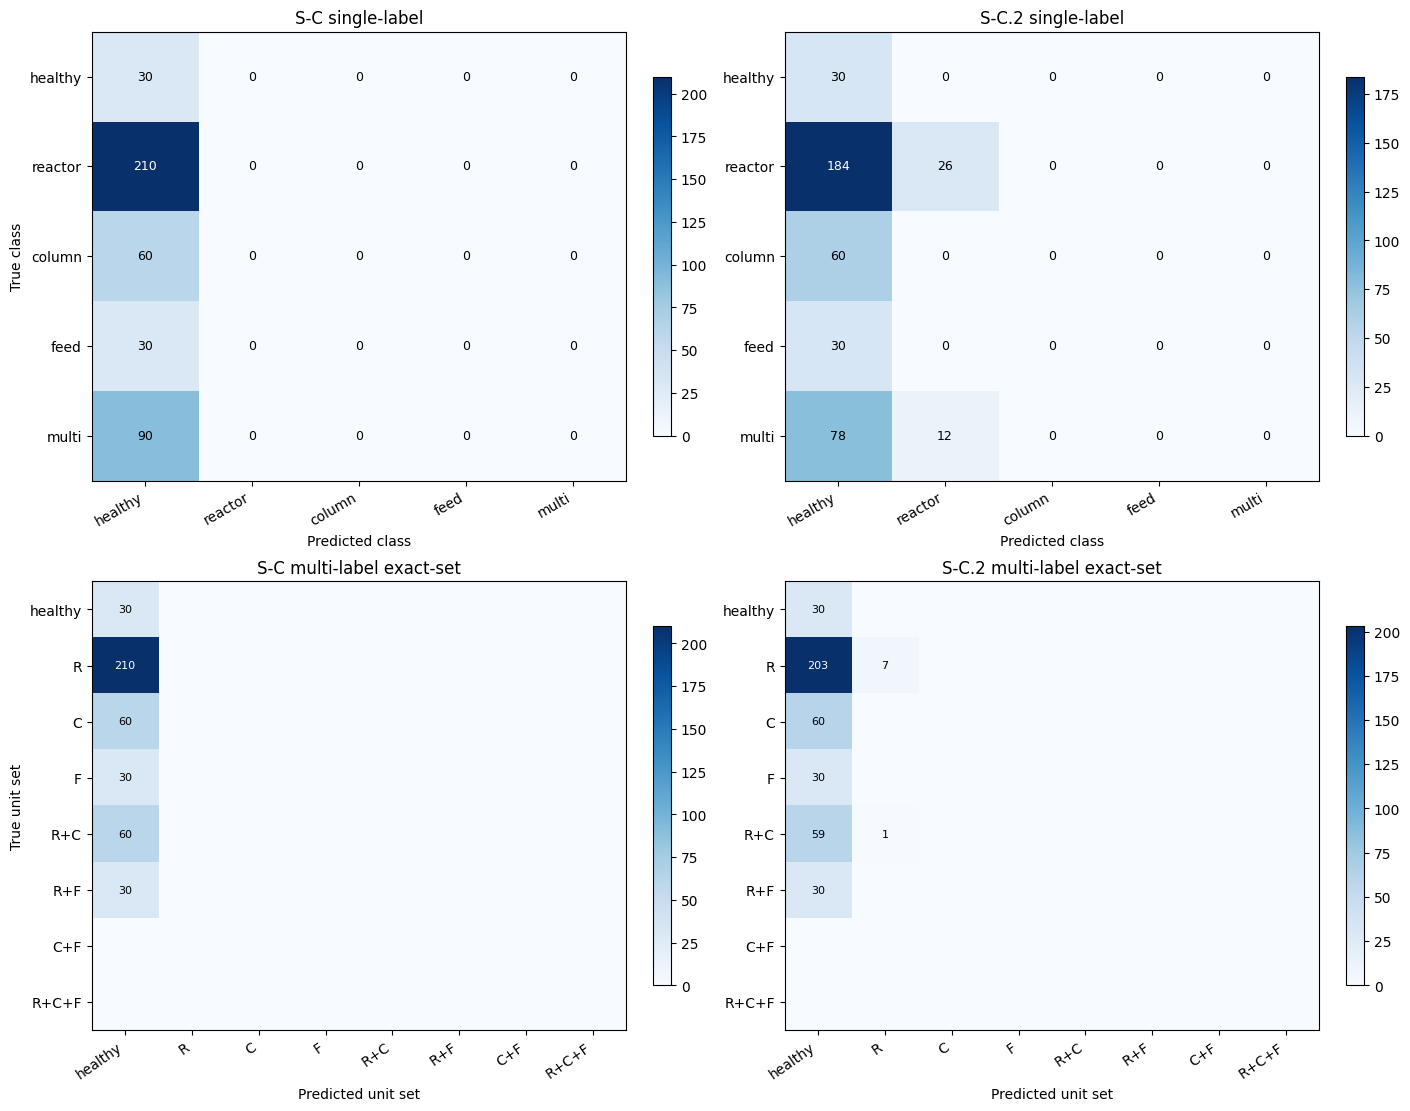

model  single_accuracy  single_macro_f1  multilabel_subset_accuracy  multilabel_macro_f1  feed_unit_f1
  S-C            0.071            0.027                       0.071                0.000         0.000
S-C.2            0.133            0.071                       0.088                0.017         0.000

S-C per-unit multi-label F1:
  reactor_present  precision=0.000 recall=0.000 f1=0.000
  column_present   precision=0.000 recall=0.000 f1=0.000
  feed_present     precision=0.000 recall=0.000 f1=0.000

S-C.2 per-unit multi-label F1:
  reactor_present  precision=1.000 recall=0.027 f1=0.052
  column_present   precision=0.000 recall=0.000 f1=0.000
  feed_present     precision=0.000 recall=0.000 f1=0.000
Saved /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/figures/31a_sc_sc2_single_multilabel_confusions.png


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)
for col, tag in enumerate(['sc', 'sc2']):
    result = results_by_tag[tag]
    single = result['single_metrics']['confusion_matrix']
    ax = axes[0, col]
    im = ax.imshow(single, cmap='Blues', aspect='auto')
    ax.set_title(f"{result['spec']['label']} single-label")
    ax.set_xticks(range(len(FAULT_UNITS)))
    ax.set_xticklabels(FAULT_UNITS, rotation=30, ha='right')
    ax.set_yticks(range(len(FAULT_UNITS)))
    ax.set_yticklabels(FAULT_UNITS)
    for i in range(len(FAULT_UNITS)):
        for j in range(len(FAULT_UNITS)):
            val = single[i, j]
            ax.text(j, i, str(val), ha='center', va='center', color='white' if val > single.max() / 2 else 'black', fontsize=9)
    plt.colorbar(im, ax=ax, shrink=0.8)

    set_labels = result['set_labels']
    set_cm = result['set_confusion_matrix']
    ax = axes[1, col]
    im = ax.imshow(set_cm, cmap='Blues', aspect='auto')
    ax.set_title(f"{result['spec']['label']} multi-label exact-set")
    ax.set_xticks(range(len(set_labels)))
    ax.set_xticklabels(set_labels, rotation=35, ha='right')
    ax.set_yticks(range(len(set_labels)))
    ax.set_yticklabels(set_labels)
    for i in range(len(set_labels)):
        for j in range(len(set_labels)):
            val = set_cm[i, j]
            if val > 0:
                ax.text(j, i, str(val), ha='center', va='center', color='white' if val > set_cm.max() / 2 else 'black', fontsize=8)
    plt.colorbar(im, ax=ax, shrink=0.8)

axes[0, 0].set_ylabel('True class')
axes[1, 0].set_ylabel('True unit set')
axes[1, 0].set_xlabel('Predicted unit set')
axes[1, 1].set_xlabel('Predicted unit set')
axes[0, 0].set_xlabel('Predicted class')
axes[0, 1].set_xlabel('Predicted class')
plt.savefig(FIGURES / '31a_sc_sc2_single_multilabel_confusions.png', dpi=200, bbox_inches='tight')
plt.show()

print(summary_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
for tag in ['sc', 'sc2']:
    result = results_by_tag[tag]
    print(f"\n{result['spec']['label']} per-unit multi-label F1:")
    for unit_label, row in result['multilabel_unit_metrics'].items():
        print(f"  {unit_label:16s} precision={row['precision']:.3f} recall={row['recall']:.3f} f1={row['f1']:.3f}")
print('Saved', FIGURES / '31a_sc_sc2_single_multilabel_confusions.png')